### Models: Waste-water + Case data

In [32]:
import pandas as pd
import numpy as np, geopandas as gpd
import rasterstats 
from rasterio import features
from pathlib import Path
import matplotlib.pyplot as plt
import subprocess
import geopandas as gpd
import covasim as cv

import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist

import nutpie
print("nutpie", nutpie.__version__)

import pytensor.tensor as pt
import arviz as az
import pymc as pm

nutpie 0.15.2


### Data

In [33]:
REPO_ROOT = Path(subprocess.check_output(["git", "rev-parse", "--show-toplevel"], text=True).strip())
SD_DATA = REPO_ROOT / "docs" / "tutorials" / "san-diego-data"

sewersheds = gpd.read_file(SD_DATA / "sandiego_sewersheds.geojson")
sewersheds.head(3)

,sewershed,sid,n_zips,geometry
0,Encina,Encina,18,"POLYGON ((-117.35784 33.1652, -117.35784 33.16..."
1,Point Loma,Point Loma,62,"POLYGON ((-117.28234 32.83273, -117.2823 32.83..."
2,South Bay,South Bay,3,"POLYGON ((-117.13708 32.57957, -117.13589 32.5..."


In [34]:
zips = gpd.read_file(SD_DATA / "sandiego_zip_boundaries.geojson")
zips.head(3)

,zip,community,sewershed,region_code,region_name,geometry
0,91901,Alpine,Point Loma,91901,Alpine,"POLYGON ((-116.74539 32.96063, -116.74085 32.9..."
1,91902,Bonita,Point Loma,91902,Bonita,"POLYGON ((-116.97172 32.70838, -116.97124 32.7..."
2,91905,Boulevard,None,91905,Boulevard,"POLYGON ((-116.23165 32.75083, -116.22809 32.7..."


In [35]:
import rasterio

with rasterio.open(SD_DATA / "san_diego_county_ppp_2020.tif") as src:
    counts = src.read(1, masked=True)      # the grid of people per cell, nodata masked out
    print(src.crs, src.shape, src.bounds)
    print(f"total pop in raster: {counts.sum():,.0f}")

INFO:rasterio._env:GDAL signalled an error: err_no=1, msg='PROJ: internal_proj_identify: /storage/hcraddock/mamba/envs/covasim/share/proj/proj.db contains DATABASE.LAYOUT.VERSION.MINOR = 5 whereas a number >= 6 is expected. It comes from another PROJ installation.'


GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]] (1189, 1842) BoundingBox(left=-117.60624951449998, bottom=32.524583404130006, right=-116.07124952063998, top=33.515416733500004)
total pop in raster: 3,554,717


### 1. Simulate epidemic

In [36]:
sim = cv.Sim(
    pop_size=100000,
    pop_type='rank',
    pop_infected=50,
    n_days=150,
    n_imports=0,
    rand_seed=1,
    density_raster=str(SD_DATA / 'san_diego_county_ppp_2020.tif'),
    boundary_shapefile=str(SD_DATA / 'sandiego_zip_boundaries.geojson'),
    sewershed_file=str(SD_DATA / 'sandiego_sewersheds.geojson'),
    interventions=[cv.test_prob(symp_prob=0.2, start_day=0)],
    verbose=0,
)
sim.initialize()        # creates the agents and builds the rank network (the slow part)

KeyboardInterrupt: 

In [ ]:
sim.run()

Sim(<no label>; 2020-03-01 to 2020-07-29; pop: 100000 rank; epi: 77048⚙, 475☠)

### ii. Case data

In [ ]:
def per_zip_day(date_array):
    """Count agents by ZIP and day, given a date for each agent (NaN = never)."""
    ok = ~np.isnan(date_array) & (date_array < T)
    out = np.zeros((n_zips, T), dtype=int)
    np.add.at(out, (agent_row[ok], date_array[ok].astype(int)), 1)
    return out

In [ ]:
#Extract data
people, T, n_zips = sim.people, sim.npts, len(zips)

# Which row of the zips table each agent lives in
zip_row = {code: i for i, code in enumerate(zips["region_code"].astype(int))}
agent_row = np.array([zip_row[c] for c in people.region])

In [ ]:
cases = per_zip_day(people.date_diagnosed)            # observed cases: ZIPs x days
infections = per_zip_day(people.date_exposed)         # true infections (ground truth, for scoring later)
N = np.bincount(agent_row, minlength=n_zips)          # agents per ZIP

print("cases shape:", cases.shape, "  total cases:", cases.sum(), "  total infections:", infections.sum())

cases shape: (113, 151)   total cases: 37438   total infections: 68492


## Plots

## I. Wastewater plot

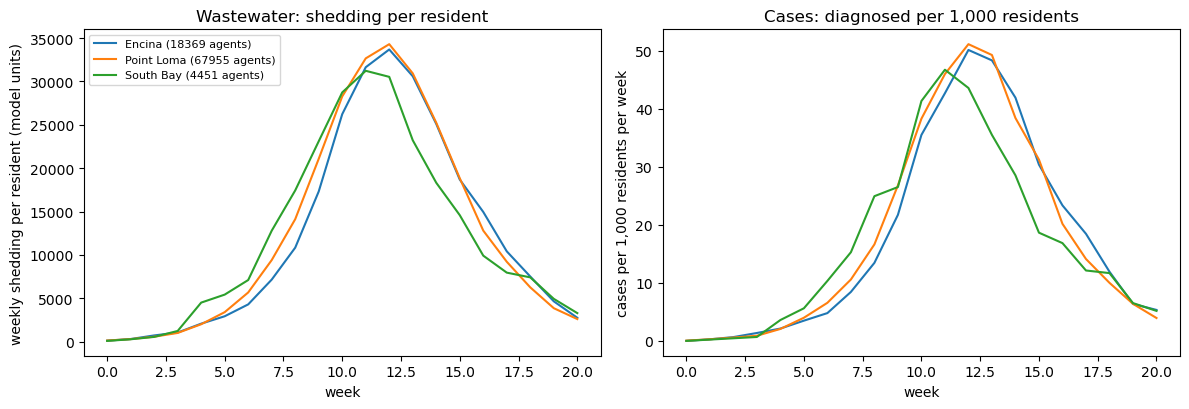

In [ ]:
people = sim.people
sewershed_of_agent = np.asarray(people.sewershed)
T = sim.npts
n_weeks_plot = T // 7
shedding = sim.results["viral_shedding_hist"]                      # (agents, days)

def weekly(daily_series):
    """Add up each block of 7 days (drops leftover days)."""
    return daily_series[:n_weeks_plot * 7].reshape(n_weeks_plot, 7).sum(axis=1)

fig, (ax_ww, ax_cases) = plt.subplots(1, 2, figsize=(12, 4.2))

for code, name in sim.sewershed_labels.items():
    in_catchment = sewershed_of_agent == code
    n_agents = in_catchment.sum()

    # Wastewater: average shedding per resident of this catchment, summed over each week (unscaled)
    ax_ww.plot(weekly(shedding[in_catchment].mean(axis=0)), label=f"{name} ({n_agents} agents)")

    # Cases: people diagnosed in this catchment each day, per 1,000 residents, summed over each week (unscaled)
    diagnosed_days = people.date_diagnosed[in_catchment & ~np.isnan(people.date_diagnosed)].astype(int)
    daily_cases = np.bincount(diagnosed_days[diagnosed_days < T], minlength=T)
    ax_cases.plot(weekly(daily_cases) / n_agents * 1000, label=name)

ax_ww.set_title("Wastewater: shedding per resident"); ax_ww.set_xlabel("week"); ax_ww.set_ylabel("weekly shedding per resident (model units)")
ax_cases.set_title("Cases: diagnosed per 1,000 residents"); ax_cases.set_xlabel("week"); ax_cases.set_ylabel("cases per 1,000 residents per week")
ax_ww.legend(fontsize=8); plt.tight_layout(); plt.show()

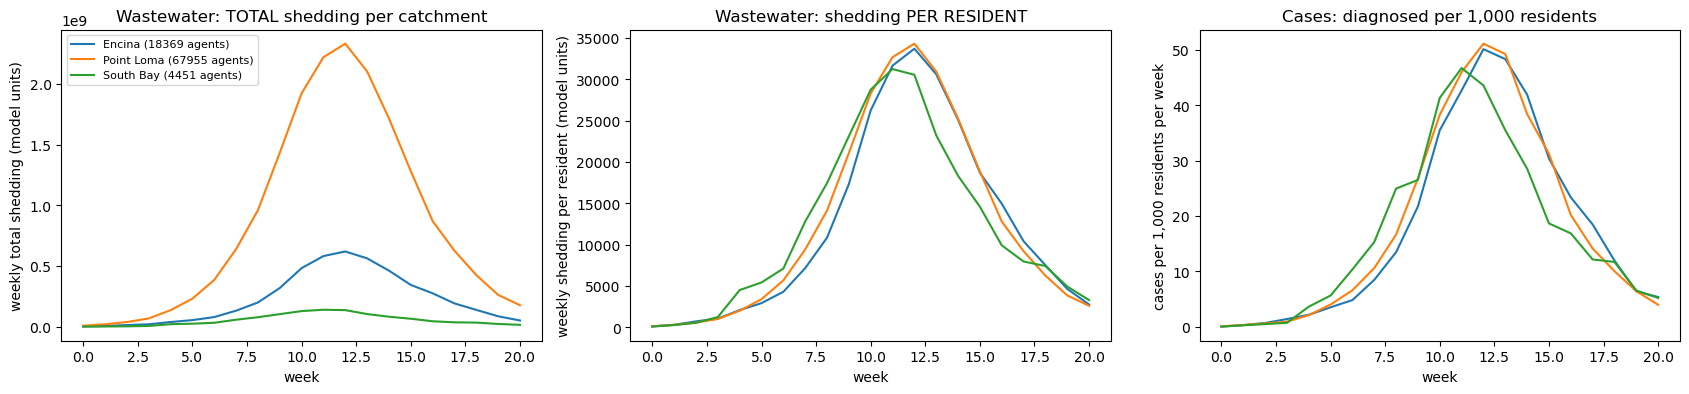

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

people = sim.people
sewershed_of_agent = np.asarray(people.sewershed)
T = sim.npts
n_weeks_plot = T // 7
shedding = sim.results["viral_shedding_hist"]                      # (agents, days)

def weekly(daily_series):
    """Add up each block of 7 days (drops leftover days)."""
    return daily_series[:n_weeks_plot * 7].reshape(n_weeks_plot, 7).sum(axis=1)

fig, (ax_total, ax_resident, ax_cases) = plt.subplots(1, 3, figsize=(17, 4.2))

for code, name in sim.sewershed_labels.items():
    in_catchment = sewershed_of_agent == code
    n_agents = in_catchment.sum()
    shed_daily_total = shedding[in_catchment].sum(axis=0)          # total shedding of everyone in the catchment, per day

    ax_total.plot(weekly(shed_daily_total), label=f"{name} ({n_agents} agents)")                 # total per catchment
    ax_resident.plot(weekly(shed_daily_total) / n_agents, label=name)                            # total divided by residents

    diagnosed_days = people.date_diagnosed[in_catchment & ~np.isnan(people.date_diagnosed)].astype(int)
    daily_cases = np.bincount(diagnosed_days[diagnosed_days < T], minlength=T)
    ax_cases.plot(weekly(daily_cases) / n_agents * 1000, label=name)                             # cases per 1,000 residents

ax_total.set_title("Wastewater: TOTAL shedding per catchment"); ax_total.set_ylabel("weekly total shedding (model units)")
ax_resident.set_title("Wastewater: shedding PER RESIDENT"); ax_resident.set_ylabel("weekly shedding per resident (model units)")
ax_cases.set_title("Cases: diagnosed per 1,000 residents"); ax_cases.set_ylabel("cases per 1,000 residents per week")
for ax in (ax_total, ax_resident, ax_cases):
    ax.set_xlabel("week")
ax_total.legend(fontsize=8); plt.tight_layout(); plt.show()

In [ ]:
people = sim.people
shed_total = sim.results["viral_shedding_hist"].sum(axis=1)       # each agent's total shedding over the run
was_diagnosed = ~np.isnan(people.date_diagnosed)
print("agents shedding but never diagnosed:", int(((shed_total > 0) & ~was_diagnosed).sum()))
print("agents shedding and diagnosed:      ", int(((shed_total > 0) & was_diagnosed).sum()))

agents shedding but never diagnosed: 30921
agents shedding and diagnosed:       37438


## Part 2: Extract data from sim

In [ ]:
people, T = sim.people, sim.npts
n_weeks = T // 7                                                          # 151 days -> 21 full weeks
n_hold = 4
sewershed_of_agent = np.asarray(people.sewershed)
shedding = sim.results["viral_shedding_hist"]                             # (agents, days)

def weekly(a):
    """Add up each block of 7 days (drops leftover days). Works on (..., days) arrays."""
    return a[..., :n_weeks * 7].reshape(*a.shape[:-1], n_weeks, 7).sum(-1)

# Cases per ZIP per day, and agents per ZIP
zip_row = {code: i for i, code in enumerate(zips["region_code"].astype(int))}
agent_row = np.array([zip_row[c] for c in people.region])
ok = ~np.isnan(people.date_diagnosed) & (people.date_diagnosed < T)
cases = np.zeros((n_zips, T), dtype=int)
np.add.at(cases, (agent_row[ok], people.date_diagnosed[ok].astype(int)), 1)
N = np.bincount(agent_row, minlength=n_zips)
zips_with_data = np.flatnonzero(N > 0)

# Wastewater: weekly shedding per resident, one row per catchment (same as your plot)
codes = sorted(sim.sewershed_labels)
wastewater = np.array([weekly(shedding[sewershed_of_agent == c].mean(axis=0)) for c in codes])      # (3, weeks)
agents_in_sewershed = np.array([(sewershed_of_agent == c).sum() for c in codes])
# share[k, i] = fraction of catchment k's agents who live in ZIP i
share = np.array([np.bincount(agent_row[sewershed_of_agent == c], minlength=n_zips) / n
                  for c, n in zip(codes, agents_in_sewershed)])

S = dict(
    n_weeks=n_weeks, n_train=n_weeks - n_hold, zips_with_data=zips_with_data,
    agents_in_zip=N[zips_with_data].astype(float), cases_w=weekly(cases)[zips_with_data],
    wastewater=wastewater, usable=wastewater > 0,                          # log needs > 0; only exact zeros are skipped
    share=share,
    zip_monitored=(((share * agents_in_sewershed[:, None]).sum(0) / np.maximum(N, 1)) >= 0.5)[zips_with_data],
)
print("weeks:", n_weeks, " train:", S["n_train"], " ZIPs with data:", len(zips_with_data),
      " monitored ZIPs:", int(S["zip_monitored"].sum()), " total cases:", cases.sum(),
      " wastewater cells used:", int(S["usable"].sum()), "of", S["usable"].size)

weeks: 21  train: 17  ZIPs with data: 112  monitored ZIPs: 84  total cases: 37438  wastewater cells used: 63 of 63


In [ ]:
S

{'n_weeks': 21,
 'n_train': 17,
 'zips_with_data': array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 111, 112]),
 'agents_in_zip': array([ 632.,  536.,   62.,  121., 2369., 2791., 1237.,  483.,  830.,
          56.,   33.,   15.,  846.,   21.,  281., 1098., 1212.,  799.,
           3., 1885.,   38.,   33., 1897.,  258.,    5.,  142.,  117.,
         324.,  904., 1346.,  490.,  716.,  421., 1329., 1886., 2044.,
        1631., 

### Part 2: model

### Adjacency

In [ ]:
n_zips = len(zips)

# Neighbours: two ZIPs are neighbours if their outlines touch (tiny buffer closes hairline gaps)
zip_shapes = zips.geometry.buffer(1e-6)
shape_index = zip_shapes.sindex
adjacency = np.zeros((n_zips, n_zips), dtype=bool)
for i, shape in enumerate(zip_shapes):
    for j in shape_index.query(shape, predicate="intersects"):
        if j != i:
            adjacency[i, j] = True
adjacency = adjacency | adjacency.T

# Join any islands to the nearest ZIP so the map is one connected piece
centroids = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])
n_pieces, piece_of_zip = connected_components(sp.csr_matrix(adjacency), directed=False)
print("separate pieces before joining:", n_pieces)
while n_pieces > 1:
    in_main = piece_of_zip == np.argmax(np.bincount(piece_of_zip))
    dist = cdist(centroids[~in_main], centroids[in_main])
    r, c = np.unravel_index(dist.argmin(), dist.shape)
    a, b = np.flatnonzero(~in_main)[r], np.flatnonzero(in_main)[c]
    print(f"linking {zips.loc[a, 'zip']} -> {zips.loc[b, 'zip']}")
    adjacency[a, b] = adjacency[b, a] = True
    n_pieces, piece_of_zip = connected_components(sp.csr_matrix(adjacency), directed=False)

neighbour_a, neighbour_b = np.where(np.triu(adjacency, 1))        # each touching pair listed once
icar_precision = np.diag(adjacency.sum(1)) - adjacency.astype(float)
bym2_scale = float(np.exp(np.mean(np.log(np.diag(np.linalg.pinv(icar_precision))))))
print("ZIPs:", n_zips, " neighbour pairs:", len(neighbour_a), " BYM2 scale:", round(bym2_scale, 3))

separate pieces before joining: 1
ZIPs: 113  neighbour pairs: 299  BYM2 scale: 0.406


/tmp/ipykernel_907522/3384746493.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  zip_shapes = zips.geometry.buffer(1e-6)
/tmp/ipykernel_907522/3384746493.py:14: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = np.column_stack([zips.geometry.centroid.x, zips.geometry.centroid.y])


In [ ]:
def fit(S, use_wastewater, draws=1500, tune=1500):
    n_weeks, n_train, zwd = S["n_weeks"], S["n_train"], S["zips_with_data"]
    cases_train = S["cases_w"][:, :n_train]                                # the model only sees these weeks of cases
    avg_rate = cases_train.sum() / (S["agents_in_zip"].sum() * n_train)

    with pm.Model():
        alpha = pm.Normal("alpha", np.log(avg_rate), 2.0)                  # intercept: average log weekly rate

        # Spatial effect u_i (BYM2): part smooth across neighbours, part per-ZIP noise
        sigma_u = pm.HalfNormal("sigma_u", 1.0)
        rho = pm.Beta("rho", 1, 1)
        u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)
        pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))
        u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)
        u = pm.Deterministic("u", sigma_u * (pt.sqrt(rho / bym2_scale) * u_smooth + pt.sqrt(1 - rho) * u_independent))

        # Time effect v_w: second-order random walk (the growth rate wanders; the level is its running total)
        g0 = pm.Normal("g0", 0.5, 1.0)
        sigma_g = pm.HalfNormal("sigma_g", 0.5)
        growth_steps = pm.Normal("growth_steps", 0, 1, shape=n_weeks)      # covers ALL weeks, incl. the 4 held-out
        v_walk = pt.cumsum(g0 + pt.cumsum(sigma_g * growth_steps))
        v = pm.Deterministic("v", v_walk - v_walk.mean())

        # Cases: observed for the training weeks only
        dispersion = pm.Exponential("dispersion", 0.1)
        eta_cases = alpha + u[zwd][:, None] + v[None, :n_train]
        pm.NegativeBinomial("cases", mu=pt.exp(eta_cases + np.log(S["agents_in_zip"])[:, None]),
                            alpha=dispersion, observed=cases_train)

        if use_wastewater:
            # Wastewater: observed for ALL weeks; a catchment sees the agent-weighted average of its ZIPs' rates
            eta_all = alpha + u[:, None] + v[None, :]
            expected_shedding = pt.dot(S["share"], pt.exp(eta_all))        # (3 catchments, weeks)
            rows, cols = np.nonzero(S["usable"])
            log_ww = np.log(S["wastewater"][rows, cols])
            log_c = pm.Normal("log_c", np.log(S["wastewater"][S["usable"]].mean() / avg_rate), 2.0)   # rate -> shedding units
            sigma_w = pm.HalfNormal("sigma_w", 0.5)                        # how far wastewater sits from the model (log scale)
            pm.Normal("wastewater", mu=(log_c + pt.log(expected_shedding))[rows, cols], sigma=sigma_w, observed=log_ww)

        return pm.sample(draws=draws, tune=tune, chains=4, target_accept=0.95, random_seed=1,
                         nuts_sampler="nutpie", progressbar=False)

In [ ]:
def score(S, idata):
    rng = np.random.default_rng(0)
    post = idata.posterior
    n_s = post.sizes["chain"] * post.sizes["draw"]
    pick = rng.choice(n_s, size=1000, replace=False)
    alpha = post["alpha"].values.reshape(n_s)[pick]
    u = post["u"].values.reshape(n_s, n_zips)[pick]
    v = post["v"].values.reshape(n_s, S["n_weeks"])[pick]
    disp = post["dispersion"].values.reshape(n_s)[pick]

    n_train, zwd = S["n_train"], S["zips_with_data"]
    mu = S["agents_in_zip"][None, :, None] * np.exp(alpha[:, None, None] + u[:, zwd, None] + v[:, None, n_train:])
    k = disp[:, None, None]
    sim_cases = rng.poisson(rng.gamma(k, mu / k))                          # (draws, ZIPs, 4 hidden weeks)

    obs = S["cases_w"][:, n_train:]                                        # hidden truth (ZIPs, 4)
    obs_county = obs.sum(0)
    lo, mid, hi = np.percentile(sim_cases.sum(1), [2.5, 50, 97.5], axis=0)
    mon, zip_err = S["zip_monitored"], np.abs(mu.mean(0) - obs)
    return {
        "county error (%)": 100 * np.mean(np.abs(mid - obs_county) / obs_county),
        "county 95% covered (of 4)": int(((obs_county >= lo) & (obs_county <= hi)).sum()),
        "interval width / observed": float(np.mean((hi - lo) / obs_county)),
        "ZIP MAE (monitored)": float(zip_err[mon].mean()),
        "ZIP MAE (unmonitored)": float(zip_err[~mon].mean()),
        "divergences": int(idata.sample_stats["diverging"].sum()),
        "worst r_hat": float(az.summary(idata, var_names=["alpha", "sigma_u", "sigma_g", "dispersion"])["r_hat"].max()),
    }

## Fit models + compare

In [ ]:
results = []
for use_ww in [False, True]:
    print("wastewater =", use_ww)
    idata = fit(S, use_ww)
    results.append({"model": "cases + wastewater" if use_ww else "cases only", **score(S, idata)})
print(pd.DataFrame(results).round(3).to_string(index=False))

wastewater = False
wastewater = True
             model  county error (%)  county 95% covered (of 4)  interval width / observed  ZIP MAE (monitored)  ZIP MAE (unmonitored)  divergences  worst r_hat
        cases only             5.118                          4                      2.511                3.376                  1.517            0         1.02
cases + wastewater            16.332                          3                      0.357                2.883                  1.867            1         1.02


## Plots

In [ ]:
idatas = {use_ww: fit(S, use_ww) for use_ww in [False, True]}

n_train = S["n_train"]
obs_county = S["cases_w"][:, n_train:].sum(0)
rng = np.random.default_rng(0)
print("observed county cases, hidden weeks:", obs_county)

for use_ww, idata in idatas.items():
    post = idata.posterior
    n_s = post.sizes["chain"] * post.sizes["draw"]
    pick = rng.choice(n_s, size=1000, replace=False)
    a = post["alpha"].values.reshape(n_s)[pick]
    u = post["u"].values.reshape(n_s, n_zips)[pick]
    v = post["v"].values.reshape(n_s, S["n_weeks"])[pick]
    mu = S["agents_in_zip"][None, :, None] * np.exp(a[:, None, None] + u[:, S["zips_with_data"], None] + v[:, None, n_train:])
    lo, mid, hi = np.percentile(mu.sum(1), [2.5, 50, 97.5], axis=0)
    print(f"wastewater={use_ww}:  forecast median {mid.round(0)}   95% range {lo.round(0)} to {hi.round(0)}")

print(az.summary(idatas[True], var_names=["sigma_w", "log_c"]))

observed county cases, hidden weeks: [1501 1092  663  447]
wastewater=False:  forecast median [1466. 1013.  691.  476.]   95% range [1037.  471.  198.   82.] to [1963. 1961. 2017. 2417.]
wastewater=True:  forecast median [1334.  862.  560.  363.]   95% range [1164.  724.  464.  276.] to [1520. 1030.  680.  477.]
           mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
sigma_w   0.271  0.029   0.221    0.327      0.000      0.0    8089.0   
log_c    13.579  0.043  13.501   13.661      0.001      0.0    6280.0   

         ess_tail  r_hat  
sigma_w    4305.0    1.0  
log_c      4894.0    1.0  


## Plot

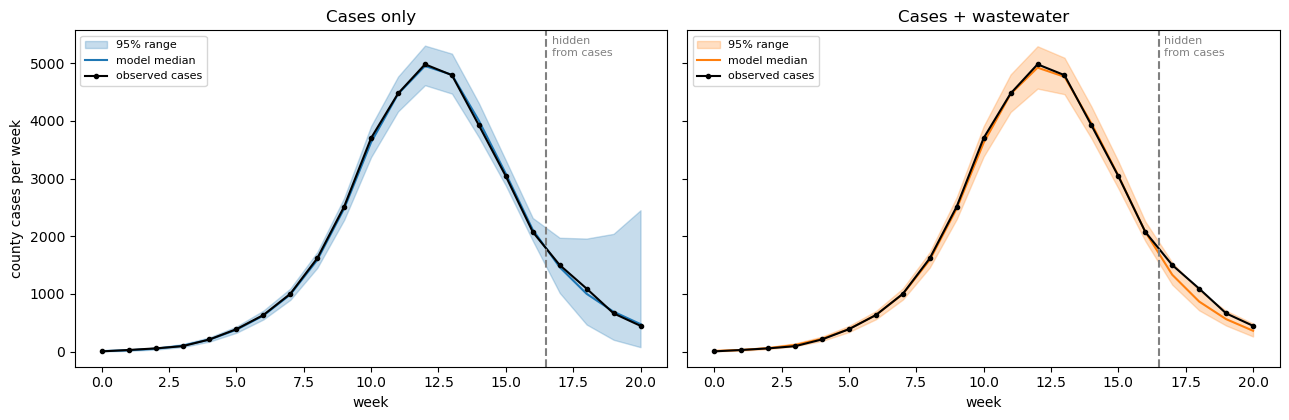

In [ ]:
rng = np.random.default_rng(0)

def county_band(idata):
    """Median and 95% range of simulated county cases, every week (training weeks are fitted, later weeks forecast)."""
    post = idata.posterior
    n_s = post.sizes["chain"] * post.sizes["draw"]
    pick = rng.choice(n_s, size=1000, replace=False)
    a = post["alpha"].values.reshape(n_s)[pick]
    u = post["u"].values.reshape(n_s, n_zips)[pick]
    v = post["v"].values.reshape(n_s, S["n_weeks"])[pick]
    disp = post["dispersion"].values.reshape(n_s)[pick]
    mu = S["agents_in_zip"][None, :, None] * np.exp(a[:, None, None] + u[:, S["zips_with_data"], None] + v[:, None, :])
    k = disp[:, None, None]
    county = rng.poisson(rng.gamma(k, mu / k)).sum(1)                    # (draws, weeks)
    return np.percentile(county, [2.5, 50, 97.5], axis=0)

observed_all = S["cases_w"].sum(0)
n_train, n_weeks = S["n_train"], S["n_weeks"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, (use_ww, title, colour) in zip(axes, [(False, "Cases only", "tab:blue"), (True, "Cases + wastewater", "tab:orange")]):
    lo, mid, hi = county_band(idatas[use_ww])
    ax.fill_between(range(n_weeks), lo, hi, color=colour, alpha=0.25, label="95% range")
    ax.plot(mid, color=colour, label="model median")
    ax.plot(range(n_weeks), observed_all, "k.-", label="observed cases")
    ax.axvline(n_train - 0.5, color="grey", ls="--")
    ax.text(n_train - 0.3, ax.get_ylim()[1] * 0.92, "hidden\nfrom cases", fontsize=8, color="grey")
    ax.set_title(title); ax.set_xlabel("week"); ax.legend(fontsize=8)
axes[0].set_ylabel("county cases per week")
plt.tight_layout(); plt.show()

### Catchment level plots

In [ ]:
cases_catchment = np.zeros((len(codes), n_weeks))
for k, c in enumerate(codes):
    in_catchment = sewershed_of_agent == c
    days = people.date_diagnosed[in_catchment & ~np.isnan(people.date_diagnosed)].astype(int)
    daily = np.bincount(days[days < T], minlength=T)
    cases_catchment[k] = weekly(daily)                                     # weekly cases in catchment k
catchment_names = [sim.sewershed_labels[c] for c in codes]
print(dict(zip(catchment_names, cases_catchment.sum(axis=1).astype(int))))

{'Encina': 6809, 'Point Loma': 25644, 'South Bay': 1577}


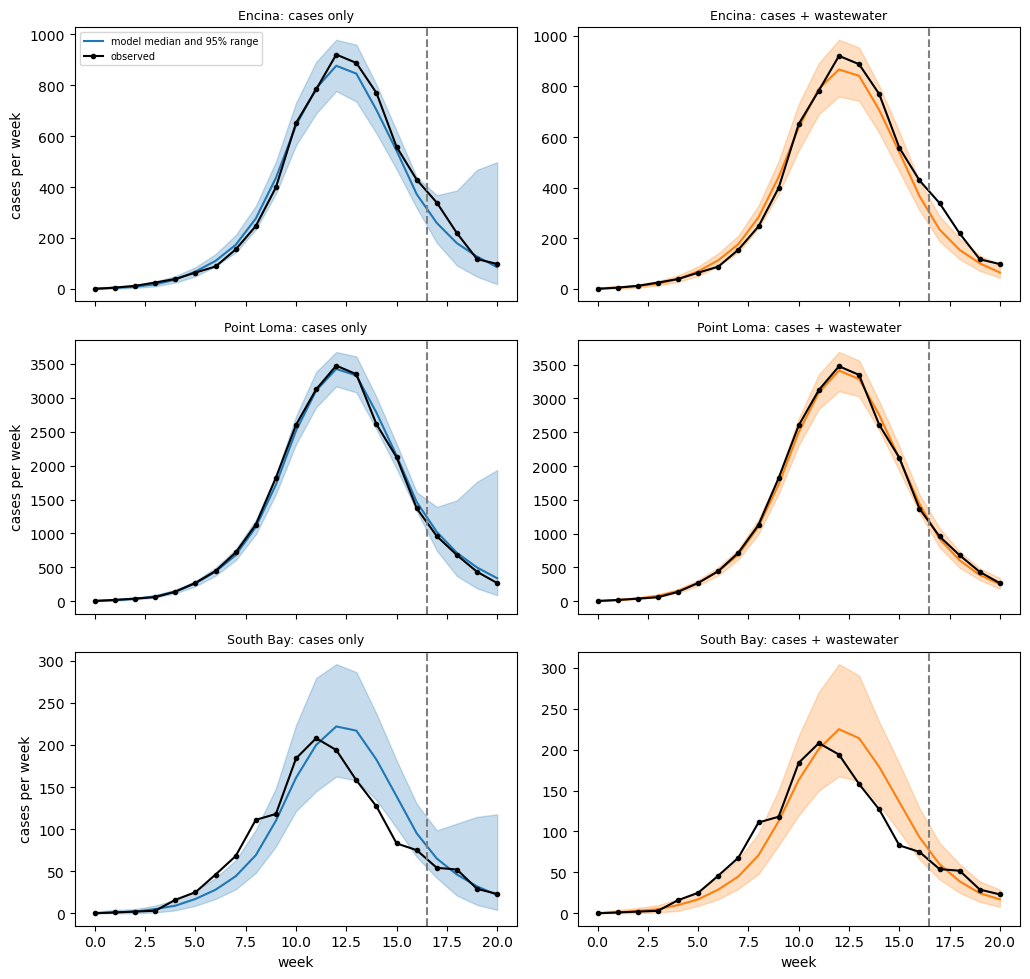

In [ ]:
def catchment_bands(idata, n_draws=500):
    """2.5%, 50%, 97.5% of simulated weekly cases per catchment: shape (3 bands, catchments, weeks)."""
    rng = np.random.default_rng(0)
    post = idata.posterior
    n_s = post.sizes["chain"] * post.sizes["draw"]
    pick = rng.choice(n_s, size=n_draws, replace=False)
    a = post["alpha"].values.reshape(n_s)[pick]
    u = post["u"].values.reshape(n_s, n_zips)[pick]
    v = post["v"].values.reshape(n_s, S["n_weeks"])[pick]
    disp = post["dispersion"].values.reshape(n_s)[pick]

    rate = np.exp(a[:, None, None] + u[:, :, None] + v[:, None, :])                          # (draws, ZIPs, weeks)
    agents_k_i = share * agents_in_sewershed[:, None]                                        # agents of ZIP i living in catchment k
    mu = agents_k_i[None, :, :, None] * rate[:, None, :, :]                                  # (draws, catchments, ZIPs, weeks)
    k = disp[:, None, None, None]
    simulated = rng.poisson(rng.gamma(k, mu / k)).sum(axis=2)                                # add up the ZIPs: (draws, catchments, weeks)
    return np.percentile(simulated, [2.5, 50, 97.5], axis=0)

def plot_catchments(models):
    """models = {title: idata}. One column per model, one row per catchment."""
    fig, axes = plt.subplots(len(codes), len(models), figsize=(5.2 * len(models), 3.3 * len(codes)), sharex=True, squeeze=False)
    colours = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
    for col, ((title, idata), colour) in enumerate(zip(models.items(), colours)):
        lo, mid, hi = catchment_bands(idata)
        for row in range(len(codes)):
            ax = axes[row, col]
            ax.fill_between(range(n_weeks), lo[row], hi[row], color=colour, alpha=0.25)
            ax.plot(mid[row], color=colour, label="model median and 95% range")
            ax.plot(cases_catchment[row], "k.-", label="observed")
            ax.axvline(S["n_train"] - 0.5, color="grey", ls="--")
            ax.set_title(f"{catchment_names[row]}: {title}", fontsize=9)
            if col == 0: ax.set_ylabel("cases per week")
            if row == len(codes) - 1: ax.set_xlabel("week")
    axes[0, 0].legend(fontsize=7)
    plt.tight_layout(); plt.show()

plot_catchments({"cases only": idatas[False], "cases + wastewater": idatas[True]})

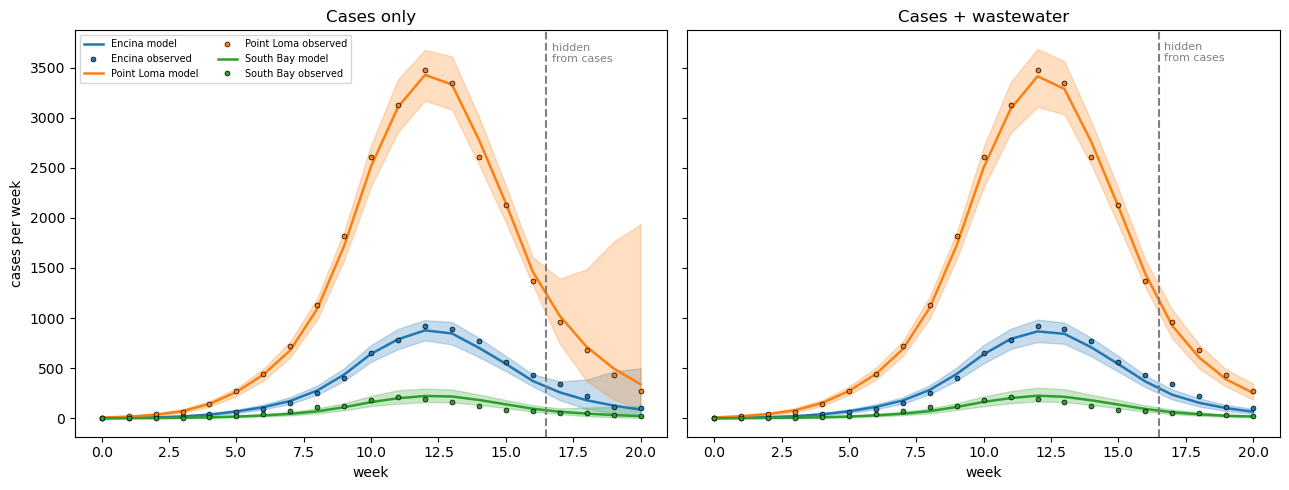

In [37]:
import numpy as np
import matplotlib.pyplot as plt

catchment_colours = ["tab:blue", "tab:orange", "tab:green"]          # one colour per catchment
models = {"Cases only": idatas[False], "Cases + wastewater": idatas[True]}
n_train, n_weeks = S["n_train"], S["n_weeks"]
weeks = np.arange(n_weeks)

fig, axes = plt.subplots(1, len(models), figsize=(6.5 * len(models), 5), sharey=True)
for ax, (title, idata) in zip(np.atleast_1d(axes), models.items()):
    lo, mid, hi = catchment_bands(idata)                              # each: (catchments, weeks)
    for k, colour in enumerate(catchment_colours[:len(codes)]):
        ax.fill_between(weeks, lo[k], hi[k], color=colour, alpha=0.25)                 # 95% range
        ax.plot(weeks, mid[k], color=colour, lw=1.8, label=f"{catchment_names[k]} model")   # model median
        ax.plot(weeks, cases_catchment[k], ".", color=colour, ms=7, markeredgecolor="k",
                markeredgewidth=0.5, label=f"{catchment_names[k]} observed")                 # observed cases
    ax.axvline(n_train - 0.5, color="grey", ls="--")
    ax.text(n_train - 0.3, ax.get_ylim()[1] * 0.92, "hidden\nfrom cases", fontsize=8, color="grey")
    ax.set_title(title); ax.set_xlabel("week")
np.atleast_1d(axes)[0].set_ylabel("cases per week")
np.atleast_1d(axes)[0].legend(fontsize=7, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

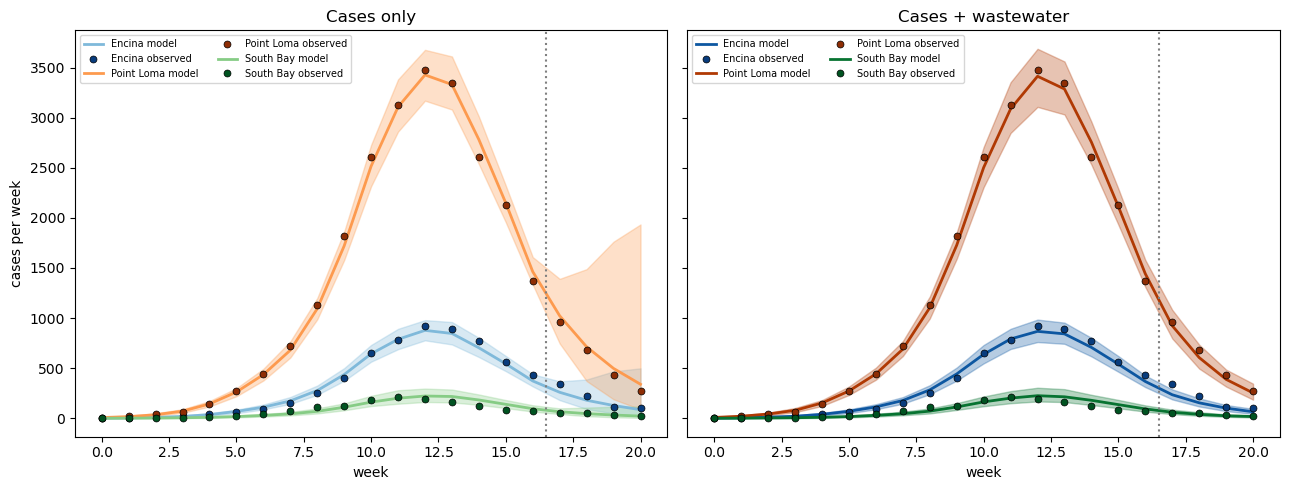

In [39]:
import numpy as np
import matplotlib.pyplot as plt

hues = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens]          # one hue per catchment: Encina, Point Loma, South Bay
panels = {"Cases only": (idatas[False], 0.45),                # (fitted model, shade: lower = lighter)
          "Cases + wastewater": (idatas[True], 0.85)}         # darker version of the same hues
n_train, n_weeks = S["n_train"], S["n_weeks"]
weeks = np.arange(n_weeks)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, (idata, shade)) in zip(axes, panels.items()):
    lo, mid, hi = catchment_bands(idata)                      # each: (catchments, weeks)
    for k in range(len(codes)):
        colour = hues[k](shade)
        ax.fill_between(weeks, lo[k], hi[k], color=colour, alpha=0.30)                  # 95% range
        ax.plot(weeks, mid[k], color=colour, lw=2, label=f"{catchment_names[k]} model")  # median
        ax.plot(weeks, cases_catchment[k], "o", color=hues[k](0.95), ms=5,
                markeredgecolor="k", markeredgewidth=0.5, label=f"{catchment_names[k]} observed")
    ax.axvline(n_train - 0.5, color="grey", ls=":")
    ax.set_title(title); ax.set_xlabel("week")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
axes[0].set_ylabel("cases per week")
plt.tight_layout(); plt.show()

### Part 3: Model + wastewater (not for last 4 days)

In [41]:
def fit(S, use_wastewater, ww_weeks=None, lag=0, draws=1500, tune=1500):
    n_weeks, n_train, zwd = S["n_weeks"], S["n_train"], S["zips_with_data"]
    cases_train = S["cases_w"][:, :n_train]
    avg_rate = cases_train.sum() / (S["agents_in_zip"].sum() * n_train)

    with pm.Model():
        alpha = pm.Normal("alpha", np.log(avg_rate), 2.0)

        sigma_u = pm.HalfNormal("sigma_u", 1.0)
        rho = pm.Beta("rho", 1, 1)
        u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)
        pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))
        u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)
        u = pm.Deterministic("u", sigma_u * (pt.sqrt(rho / bym2_scale) * u_smooth + pt.sqrt(1 - rho) * u_independent))

        g0 = pm.Normal("g0", 0.5, 1.0)
        sigma_g = pm.HalfNormal("sigma_g", 0.5)
        growth_steps = pm.Normal("growth_steps", 0, 1, shape=n_weeks)
        v_walk = pt.cumsum(g0 + pt.cumsum(sigma_g * growth_steps))
        v = pm.Deterministic("v", v_walk - v_walk.mean())

        dispersion = pm.Exponential("dispersion", 0.1)
        eta_cases = alpha + u[zwd][:, None] + v[None, :n_train]
        pm.NegativeBinomial("cases", mu=pt.exp(eta_cases + np.log(S["agents_in_zip"])[:, None]),
                            alpha=dispersion, observed=cases_train)

        if use_wastewater:
            # Wastewater week w is paired with the case rate in week w + lag.
            # ww_weeks = how many weeks of wastewater the model gets to see (None = all of them).
            n_ww = min(n_weeks if ww_weeks is None else ww_weeks, n_weeks - lag)
            eta_all = alpha + u[:, None] + v[None, :]
            expected_shedding = pt.dot(S["share"], pt.exp(eta_all))[:, lag:lag + n_ww]
            ww_used = S["wastewater"][:, :n_ww]
            rows, cols = np.nonzero(ww_used > 0)
            log_c = pm.Normal("log_c", np.log(ww_used[ww_used > 0].mean() / avg_rate), 2.0)
            sigma_w = pm.HalfNormal("sigma_w", 0.5)
            pm.Normal("wastewater", mu=(log_c + pt.log(expected_shedding))[rows, cols], sigma=sigma_w,
                      observed=np.log(ww_used[rows, cols]))

        return pm.sample(draws=draws, tune=tune, chains=4, target_accept=0.95, random_seed=1,
                         nuts_sampler="nutpie", progressbar=False)

In [42]:
#Fit
idatas["ww hidden"] = fit(S, True, ww_weeks=S["n_train"])

## Compare

In [43]:
print(list(idatas.keys()))                                                   # should show False, True, 'ww hidden'
print(az.summary(idatas["ww hidden"], var_names=["alpha", "sigma_u", "sigma_g", "dispersion", "sigma_w", "log_c"]).round(3))
print("divergences:", int(idatas["ww hidden"].sample_stats["diverging"].sum()))

[False, True, 'ww hidden']
              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
alpha       -4.924  0.081  -5.068   -4.763      0.003    0.002     631.0   
sigma_u      0.067  0.014   0.041    0.093      0.000    0.000    1668.0   
sigma_g      0.130  0.029   0.082    0.185      0.004    0.002      54.0   
dispersion  28.928  2.992  23.328   34.347      0.027    0.044   12941.0   
sigma_w      0.295  0.032   0.236    0.354      0.000    0.000    9485.0   
log_c       13.592  0.046  13.506   13.679      0.001    0.001    8596.0   

            ess_tail  r_hat  
alpha         1120.0   1.00  
sigma_u       2135.0   1.00  
sigma_g        217.0   1.06  
dispersion    4528.0   1.00  
sigma_w       4471.0   1.00  
log_c         4014.0   1.00  
divergences: 0


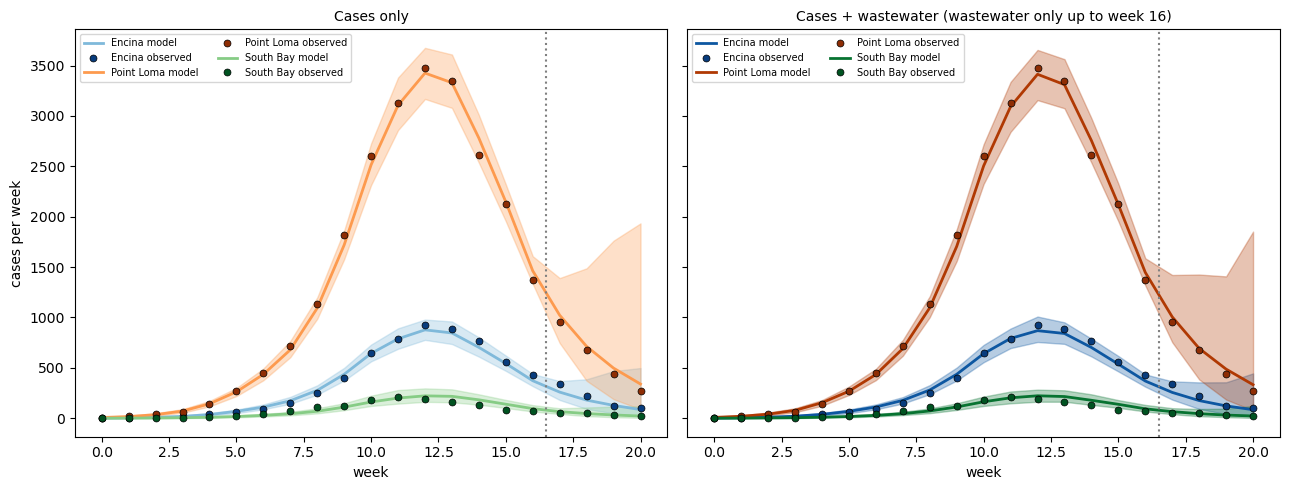

In [44]:
import numpy as np
import matplotlib.pyplot as plt

hues = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens]             # one hue per catchment
panels = {"Cases only": (idatas[False], 0.45),
          "Cases + wastewater (wastewater only up to week 16)": (idatas["ww hidden"], 0.85)}
n_train, n_weeks = S["n_train"], S["n_weeks"]
weeks = np.arange(n_weeks)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, (idata, shade)) in zip(axes, panels.items()):
    lo, mid, hi = catchment_bands(idata)
    for k in range(len(codes)):
        colour = hues[k](shade)
        ax.fill_between(weeks, lo[k], hi[k], color=colour, alpha=0.30)
        ax.plot(weeks, mid[k], color=colour, lw=2, label=f"{catchment_names[k]} model")
        ax.plot(weeks, cases_catchment[k], "o", color=hues[k](0.95), ms=5,
                markeredgecolor="k", markeredgewidth=0.5, label=f"{catchment_names[k]} observed")
    ax.axvline(n_train - 0.5, color="grey", ls=":")
    ax.set_title(title, fontsize=10); ax.set_xlabel("week")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
axes[0].set_ylabel("cases per week")
plt.tight_layout(); plt.show()

## Improve model

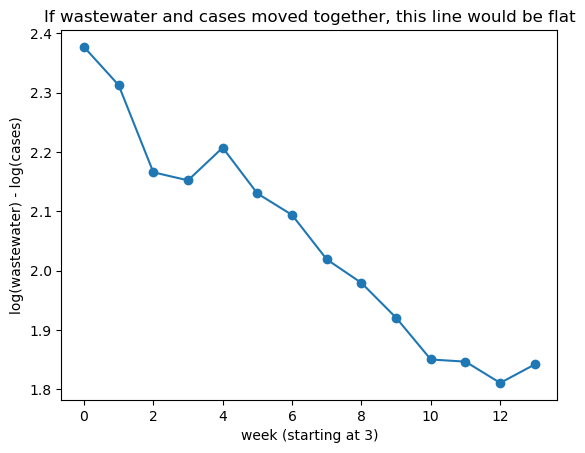

In [45]:
import numpy as np, matplotlib.pyplot as plt

n_train = S["n_train"]
ww_county = np.average(S["wastewater"], axis=0, weights=agents_in_sewershed)
cases_county = S["cases_w"].sum(0)

plt.plot(np.log(ww_county[3:n_train]) - np.log(cases_county[3:n_train]), "o-")
plt.xlabel("week (starting at 3)"); plt.ylabel("log(wastewater) - log(cases)")
plt.title("If wastewater and cases moved together, this line would be flat"); plt.show()

### Determining waste-water lag

In [49]:
print("initialized:", sim.initialized, "  run finished:", sim.complete, "  has people:", sim.people is not None)

initialized: False   run finished: False   has people: False


In [47]:
people, T = sim.people, sim.npts

In [50]:
print("shedding" in globals(), "cases" in globals())

True True


In [52]:
shed_daily = shedding.sum(axis=0)                 # total shedding of all agents, per day
cases_daily = cases.sum(axis=0)                   # total diagnosed cases, per day
days = np.arange(len(cases_daily))

centre_shed = (shed_daily * days).sum() / shed_daily.sum()
centre_cases = (cases_daily * days).sum() / cases_daily.sum()
print(f"average day of shedding: {centre_shed:.1f}   average day of cases: {centre_cases:.1f}")
print(f"cases lag wastewater by about {centre_cases - centre_shed:.1f} days = {(centre_cases - centre_shed)/7:.2f} weeks")
print(f"shedding peaks on day {shed_daily.argmax()}   cases peak on day {cases_daily.argmax()}")

def corr_at_shift(d):
    return np.corrcoef(shed_daily[:len(days) - d], cases_daily[d:])[0, 1]
best = max(range(0, 15), key=corr_at_shift)
print(f"best match when cases are shifted {best} days; correlation {corr_at_shift(best):.4f}")

average day of shedding: 87.1   average day of cases: 89.4
cases lag wastewater by about 2.3 days = 0.33 weeks
shedding peaks on day 85   cases peak on day 91
best match when cases are shifted 2 days; correlation 0.9976


In [ ]:
#How:
#sliding the cases curve earlier by 0 to 14 days
# picking the shift: highest correlation with the shedding curve

train_days = S["n_train"] * 7                                           # days 0 to 118 only
shed_tr, cases_tr = shed_daily[:train_days], cases_daily[:train_days]
t = np.arange(train_days)
print(f"training-only: cases lag wastewater by {(cases_tr*t).sum()/cases_tr.sum() - (shed_tr*t).sum()/shed_tr.sum():.1f} days")

def corr_at_shift_train(d):
    return np.corrcoef(shed_tr[:train_days - d], cases_tr[d:])[0, 1]
print("best shift from training days only:", max(range(0, 15), key=corr_at_shift_train), "days")

training-only: cases lag wastewater by 2.0 days
best shift from training days only: 2 days


## Part 3: cases + wastewater model with a 2-day lag

Cases trail wastewater by about 2 days (estimated on training days only: average-day and best-shift methods agree).
We line the two series up by delaying the wastewater by 2 days, then fit the same model as before.
Wastewater is available only up to week 16, the same cutoff as the cases, so the last 4 weeks are a true forecast.

In [54]:
shift_days = 2                                                    # cases trail wastewater by 2 days (training days only)

def shifted_weekly_wastewater(code):
    daily = shedding[sewershed_of_agent == code].mean(axis=0)     # shedding per resident, per day, for one catchment
    daily = np.concatenate([np.zeros(shift_days), daily[:-shift_days]])      # delay by 2 days: today's value moves to 2 days later
    return weekly(daily)                                          # add up each 7-day block

S["wastewater"] = np.array([shifted_weekly_wastewater(c) for c in codes])    # (3 catchments, weeks), now aligned with cases
print("wastewater table:", S["wastewater"].shape, " min:", S["wastewater"].min().round(4))

wastewater table: (3, 21)  min: 29.3251


In [55]:
c = codes[0]
orig = shedding[sewershed_of_agent == c].mean(axis=0)
shifted = np.concatenate([np.zeros(shift_days), orig[:-shift_days]])

print("day:      ", np.arange(0, 8))
print("original: ", orig[:8].round(5))
print("shifted:  ", shifted[:8].round(5), "  <- first 2 days are padding")
print("weekly wastewater week 0 uses shifted days 0-6, which are original days 0-4")
print("original days used overall: 0 to", 21 * 7 - 1 - shift_days)

day:       [0 1 2 3 4 5 6 7]
original:  [ 0.       0.       0.      17.16376 20.99018 28.83636 31.8014  23.76167]
shifted:   [ 0.       0.       0.       0.       0.      17.16376 20.99018 28.83636]   <- first 2 days are padding
weekly wastewater week 0 uses shifted days 0-6, which are original days 0-4
original days used overall: 0 to 144


#### Check shift

In [57]:
n_train = S["n_train"]

# 1. Is S["wastewater"] the 2-day-shifted table, shifted exactly once?
def weekly_ww(code, shift):
    daily = shedding[sewershed_of_agent == code].mean(axis=0)
    if shift:
        daily = np.concatenate([np.zeros(shift), daily[:-shift]])
    return weekly(daily)

unshifted = np.array([weekly_ww(c, 0) for c in codes])
shifted_once = np.array([weekly_ww(c, 2) for c in codes])
print("matches shifted-once table :", np.allclose(S["wastewater"], shifted_once))
print("matches UNshifted table    :", np.allclose(S["wastewater"], unshifted), "  (should be False)")

# 2. Which weeks does the fit actually see?
print("cases weeks used           :", S["cases_w"][:, :n_train].shape[1], "(want 17)")
print("wastewater weeks used      :", S["wastewater"][:, :n_train].shape[1], "(want 17)")
print("wastewater zeros skipped   :", int((S["wastewater"][:, :n_train] <= 0).sum()), "of", S["wastewater"][:, :n_train].size)

# 3. Is the case table the right run? (cases come from the 37,438-case epidemic)
print("total cases in S, all weeks:", int(S["cases_w"].sum()), " (daily table total:", int(cases.sum()), ")")
print("catchment order            :", catchment_names, " agents:", agents_in_sewershed)
print("share rows sum to 1        :", np.allclose(S["share"].sum(axis=1), 1))

matches shifted-once table : True
matches UNshifted table    : False   (should be False)
cases weeks used           : 17 (want 17)
wastewater weeks used      : 17 (want 17)
wastewater zeros skipped   : 0 of 51
total cases in S, all weeks: 37253  (daily table total: 37438 )
catchment order            : ['Encina', 'Point Loma', 'South Bay']  agents: [18369 67955  4451]
share rows sum to 1        : True


## Refit

In [58]:
idatas["ww aligned hidden"] = fit(S, True, ww_weeks=S["n_train"], draws=2500, tune=2500)
print(az.summary(idatas["ww aligned hidden"], var_names=["alpha", "sigma_g", "sigma_w", "log_c"]).round(3))
print("divergences:", int(idatas["ww aligned hidden"].sample_stats["diverging"].sum()))

           mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
alpha    -4.961  0.115  -5.177   -4.736      0.004    0.003     808.0   
sigma_g   0.191  0.052   0.101    0.284      0.005    0.002     113.0   
sigma_w   0.253  0.028   0.202    0.308      0.001    0.000    2210.0   
log_c    13.514  0.041  13.437   13.591      0.000    0.000   14765.0   

         ess_tail  r_hat  
alpha      1214.0   1.01  
sigma_g     210.0   1.02  
sigma_w    5154.0   1.00  
log_c      7901.0   1.00  
divergences: 1


In [59]:
import pandas as pd
rows = [{"model": name, **score(S, idatas[key])} for name, key in
        [("cases only", False),
         ("cases + wastewater, not aligned", "ww hidden"),
         ("cases + wastewater, 2-day lag", "ww aligned hidden")]]
print(pd.DataFrame(rows).round(3).to_string(index=False))

                          model  county error (%)  county 95% covered (of 4)  interval width / observed  ZIP MAE (monitored)  ZIP MAE (unmonitored)  divergences  worst r_hat
                     cases only             5.118                          4                      2.511                3.376                  1.517            0         1.02
cases + wastewater, not aligned             4.932                          4                      2.459                3.330                  1.526            0         1.06
  cases + wastewater, 2-day lag             5.594                          4                      3.986                3.988                  1.482            1         1.02


## Plot

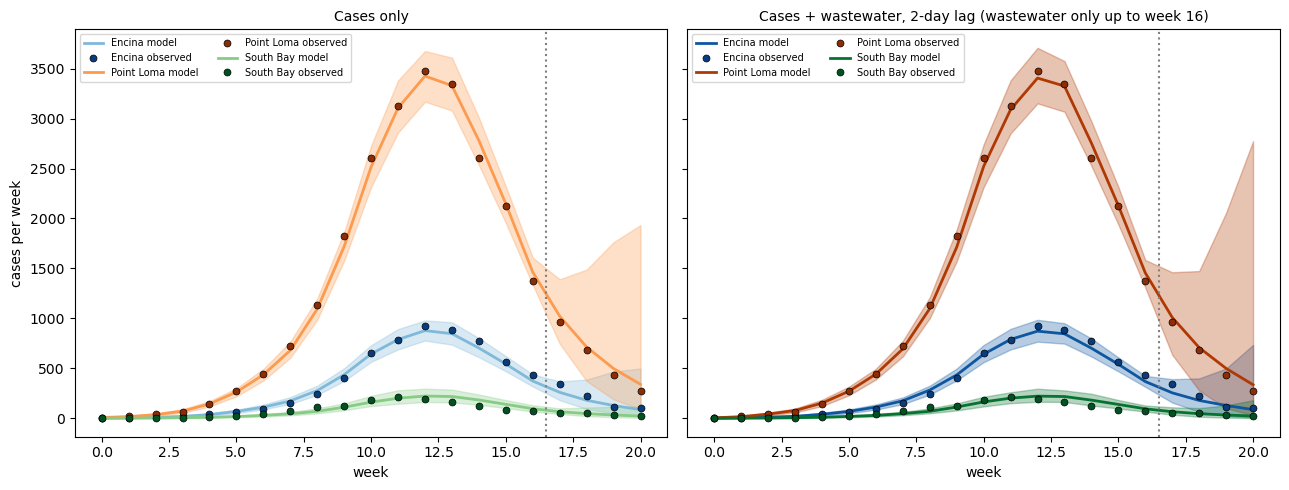

In [60]:
hues = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens]             # one hue per catchment

panels = {"Cases only": (idatas[False], 0.45),
          "Cases + wastewater, 2-day lag (wastewater only up to week 16)": (idatas["ww aligned hidden"], 0.85)}
n_train, n_weeks = S["n_train"], S["n_weeks"]
weeks = np.arange(n_weeks)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, (idata, shade)) in zip(axes, panels.items()):
    lo, mid, hi = catchment_bands(idata)
    for k in range(len(codes)):
        colour = hues[k](shade)
        ax.fill_between(weeks, lo[k], hi[k], color=colour, alpha=0.30)
        ax.plot(weeks, mid[k], color=colour, lw=2, label=f"{catchment_names[k]} model")
        ax.plot(weeks, cases_catchment[k], "o", color=hues[k](0.95), ms=5,
                markeredgecolor="k", markeredgewidth=0.5, label=f"{catchment_names[k]} observed")
    ax.axvline(n_train - 0.5, color="grey", ls=":")
    ax.set_title(title, fontsize=10); ax.set_xlabel("week")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
axes[0].set_ylabel("cases per week")
plt.tight_layout(); plt.show()

In [61]:
import numpy as np, arviz as az

for name, key in [("cases only", False), ("ww hidden, no lag", "ww hidden"), ("ww hidden, 2-day lag", "ww aligned hidden")]:
    sg = az.summary(idatas[key], var_names=["sigma_g"]).loc["sigma_g"]
    p = idatas[key].posterior
    g0 = p["g0"].values.reshape(-1); s = p["sigma_g"].values.reshape(-1)
    steps = p["growth_steps"].values.reshape(len(g0), -1)
    growth_week16 = (g0[:, None] + np.cumsum(s[:, None] * steps, axis=1))[:, S["n_train"] - 1]       # growth rate at the forecast start
    print(f"{name:22s} sigma_g {sg['mean']:.3f} (r_hat {sg['r_hat']:.2f}, ess {sg['ess_bulk']:.0f})   "
          f"growth at week 16: {growth_week16.mean():+.3f} +/- {growth_week16.std():.3f}")

cases only             sigma_g 0.139 (r_hat 1.02, ess 75)   growth at week 16: -0.377 +/- 0.038
ww hidden, no lag      sigma_g 0.130 (r_hat 1.06, ess 54)   growth at week 16: -0.376 +/- 0.037
ww hidden, 2-day lag   sigma_g 0.191 (r_hat 1.02, ess 113)   growth at week 16: -0.380 +/- 0.039


## Fit

In [65]:
def fit(S, use_wastewater, ww_weeks=None, ww_trend=False, sigma_g_value = 0.15, draws=1500, tune=1500):
    n_weeks, n_train, zwd = S["n_weeks"], S["n_train"], S["zips_with_data"]
    cases_train = S["cases_w"][:, :n_train]
    avg_rate = cases_train.sum() / (S["agents_in_zip"].sum() * n_train)

    with pm.Model():
        alpha = pm.Normal("alpha", np.log(avg_rate), 2.0)

        sigma_u = pm.HalfNormal("sigma_u", 1.0)
        rho = pm.Beta("rho", 1, 1)
        u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)
        pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))
        u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)
        u = pm.Deterministic("u", sigma_u * (pt.sqrt(rho / bym2_scale) * u_smooth + pt.sqrt(1 - rho) * u_independent))

        g0 = pm.Normal("g0", 0.5, 1.0)
        sigma_g = sigma_g_value #pm.HalfNormal("sigma_g", 0.2)
        growth_steps = pm.Normal("growth_steps", 0, 1, shape=n_weeks)
        v_walk = pt.cumsum(g0 + pt.cumsum(sigma_g * growth_steps))
        v = pm.Deterministic("v", v_walk - v_walk.mean())

        dispersion = pm.Exponential("dispersion", 0.1)
        eta_cases = alpha + u[zwd][:, None] + v[None, :n_train]
        pm.NegativeBinomial("cases", mu=pt.exp(eta_cases + np.log(S["agents_in_zip"])[:, None]),
                            alpha=dispersion, observed=cases_train)

        if use_wastewater:
            # ww_weeks = how many weeks of wastewater the model gets to see (None = all of them).
            # The 2-day lag is already in S["wastewater"], so the model pairs week w with week w.
            n_ww = n_weeks if ww_weeks is None else ww_weeks
            eta_all = alpha + u[:, None] + v[None, :]
            expected_shedding = pt.dot(S["share"], pt.exp(eta_all))[:, :n_ww]
            ww_used = S["wastewater"][:, :n_ww]
            rows, cols = np.nonzero(ww_used > 0)
            log_c = pm.Normal("log_c", np.log(ww_used[ww_used > 0].mean() / avg_rate), 2.0)
            sigma_w = pm.HalfNormal("sigma_w", 0.5)
            mean_log = log_c + pt.log(expected_shedding)                       # (catchments, weeks)
            if ww_trend:
                # The conversion drifts linearly: wastewater per case rate changes by ww_trend_slope (log scale) each week
                ww_trend_slope = pm.Normal("ww_trend_slope", 0, 0.1)
                week_centred = np.arange(n_ww) - (n_ww - 1) / 2
                mean_log = mean_log + ww_trend_slope * week_centred[None, :]
            pm.Normal("wastewater", mu=mean_log[rows, cols], sigma=sigma_w,
                      observed=np.log(ww_used[rows, cols]))

        return pm.sample(draws=draws, tune=tune, chains=4, target_accept=0.95, random_seed=1,
                         nuts_sampler="nutpie", progressbar=False)

In [63]:
idatas3 = {
    "cases only":          fit(S, False),
    "ww aligned + drift":  fit(S, True, ww_weeks=S["n_train"], ww_trend=True),
}
print(pd.DataFrame([{"model": k, **score(S, v)} for k, v in idatas3.items()]).round(3).to_string(index=False))
print(az.summary(idatas3["ww aligned + drift"], var_names=["sigma_w", "ww_trend_slope", "sigma_g"]).round(3))

             model  county error (%)  county 95% covered (of 4)  interval width / observed  ZIP MAE (monitored)  ZIP MAE (unmonitored)  divergences  worst r_hat
        cases only             6.475                          4                      2.278                3.379                  1.516            2         1.02
ww aligned + drift             5.232                          4                      7.936                5.909                  1.766            0         1.25
                 mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
sigma_w         0.213  0.024   0.173    0.259      0.001    0.000    1691.0   
ww_trend_slope -0.032  0.008  -0.046   -0.018      0.000    0.000    4289.0   
sigma_g         0.223  0.057   0.129    0.335      0.015    0.004      13.0   

                ess_tail  r_hat  
sigma_w           3723.0   1.00  
ww_trend_slope    4567.0   1.00  
sigma_g             44.0   1.25  


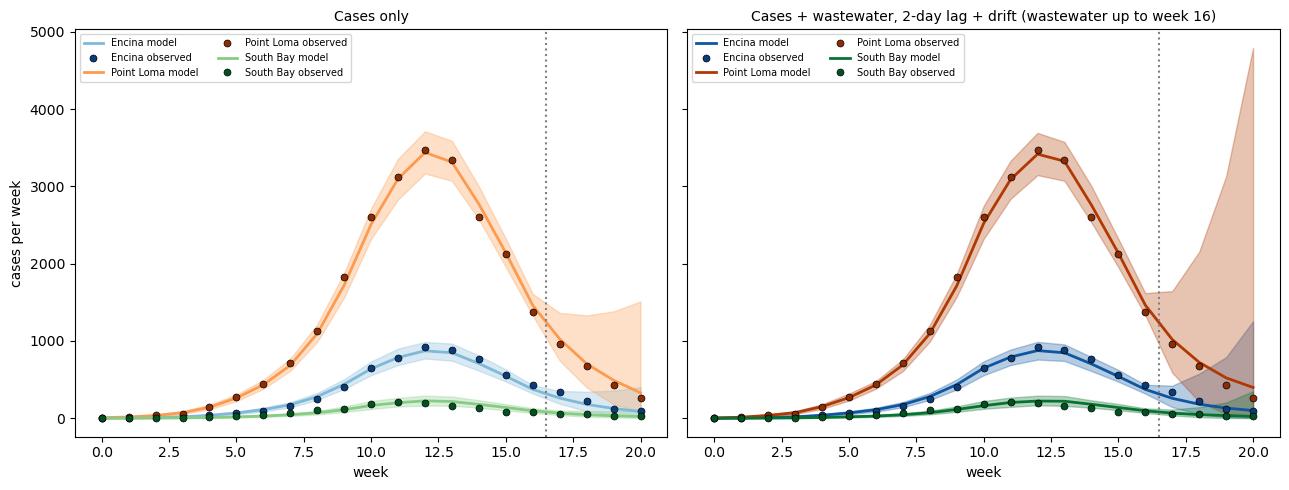

In [64]:
import numpy as np
import matplotlib.pyplot as plt

hues = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens]             # one hue per catchment
panels = {"Cases only": (idatas3["cases only"], 0.45),
          "Cases + wastewater, 2-day lag + drift (wastewater up to week 16)": (idatas3["ww aligned + drift"], 0.85)}
n_train, n_weeks = S["n_train"], S["n_weeks"]
weeks = np.arange(n_weeks)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, (idata, shade)) in zip(axes, panels.items()):
    lo, mid, hi = catchment_bands(idata)
    for k in range(len(codes)):
        colour = hues[k](shade)
        ax.fill_between(weeks, lo[k], hi[k], color=colour, alpha=0.30)
        ax.plot(weeks, mid[k], color=colour, lw=2, label=f"{catchment_names[k]} model")
        ax.plot(weeks, cases_catchment[k], "o", color=hues[k](0.95), ms=5,
                markeredgecolor="k", markeredgewidth=0.5, label=f"{catchment_names[k]} observed")
    ax.axvline(n_train - 0.5, color="grey", ls=":")
    ax.set_title(title, fontsize=10); ax.set_xlabel("week")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
axes[0].set_ylabel("cases per week")
plt.tight_layout(); plt.show()

## run 3

In [ ]:
def fit(S, use_wastewater, ww_weeks=None, ww_trend=False, draws=1500, tune=1500):

    n_weeks, n_train, zwd = S["n_weeks"], S["n_train"], S["zips_with_data"]
    cases_train = S["cases_w"][:, :n_train]
    avg_rate = cases_train.sum() / (S["agents_in_zip"].sum() * n_train)

    with pm.Model():
        alpha = pm.Normal("alpha", np.log(avg_rate), 2.0)

        sigma_u = pm.HalfNormal("sigma_u", 1.0)
        rho = pm.Beta("rho", 1, 1)
        u_smooth = pm.ZeroSumNormal("u_smooth", sigma=5.0, shape=n_zips)
        pm.Potential("icar", -0.5 * pt.sum((u_smooth[neighbour_a] - u_smooth[neighbour_b]) ** 2))
        u_independent = pm.Normal("u_independent", 0, 1, shape=n_zips)
        u = pm.Deterministic("u", sigma_u * (pt.sqrt(rho / bym2_scale) * u_smooth + pt.sqrt(1 - rho) * u_independent))

        g0 = pm.Normal("g0", 0.5, 1.0)
        sigma_g = pm.HalfNormal("sigma_g", 0.2)
        growth_steps = pm.Normal("growth_steps", 0, 1, shape=n_weeks)
        v_walk = pt.cumsum(g0 + pt.cumsum(sigma_g * growth_steps))
        v = pm.Deterministic("v", v_walk - v_walk.mean())

        dispersion = pm.Exponential("dispersion", 0.1)
        eta_cases = alpha + u[zwd][:, None] + v[None, :n_train]
        pm.NegativeBinomial("cases", mu=pt.exp(eta_cases + np.log(S["agents_in_zip"])[:, None]),
                            alpha=dispersion, observed=cases_train)

        if use_wastewater:
            # ww_weeks = how many weeks of wastewater the model gets to see (None = all of them).
            # The 2-day lag is already in S["wastewater"], so the model pairs week w with week w.
            n_ww = n_weeks if ww_weeks is None else ww_weeks
            eta_all = alpha + u[:, None] + v[None, :]
            expected_shedding = pt.dot(S["share"], pt.exp(eta_all))[:, :n_ww]
            ww_used = S["wastewater"][:, :n_ww]
            rows, cols = np.nonzero(ww_used > 0)
            log_c = pm.Normal("log_c", np.log(ww_used[ww_used > 0].mean() / avg_rate), 2.0)
            sigma_w = pm.HalfNormal("sigma_w", 0.5)
            mean_log = log_c + pt.log(expected_shedding)                       # (catchments, weeks)
            if ww_trend:
                # The conversion drifts linearly: wastewater per case rate changes by ww_trend_slope (log scale) each week
                ww_trend_slope = pm.Normal("ww_trend_slope", 0, 0.1)
                week_centred = np.arange(n_ww) - (n_ww - 1) / 2
                mean_log = mean_log + ww_trend_slope * week_centred[None, :]
            pm.Normal("wastewater", mu=mean_log[rows, cols], sigma=sigma_w,
                      observed=np.log(ww_used[rows, cols]))

        return pm.sample(draws=draws, tune=tune, chains=4, target_accept=0.95, random_seed=1,
                         nuts_sampler="nutpie", progressbar=False)

In [ ]:
idatas3 = {
    "cases only":          fit(S, False),
    "ww aligned + drift":  fit(S, True, ww_weeks=S["n_train"], ww_trend=True),
}


KeyError: 'var names: "[\'sigma_g\'] are not present" in dataset'

#QE

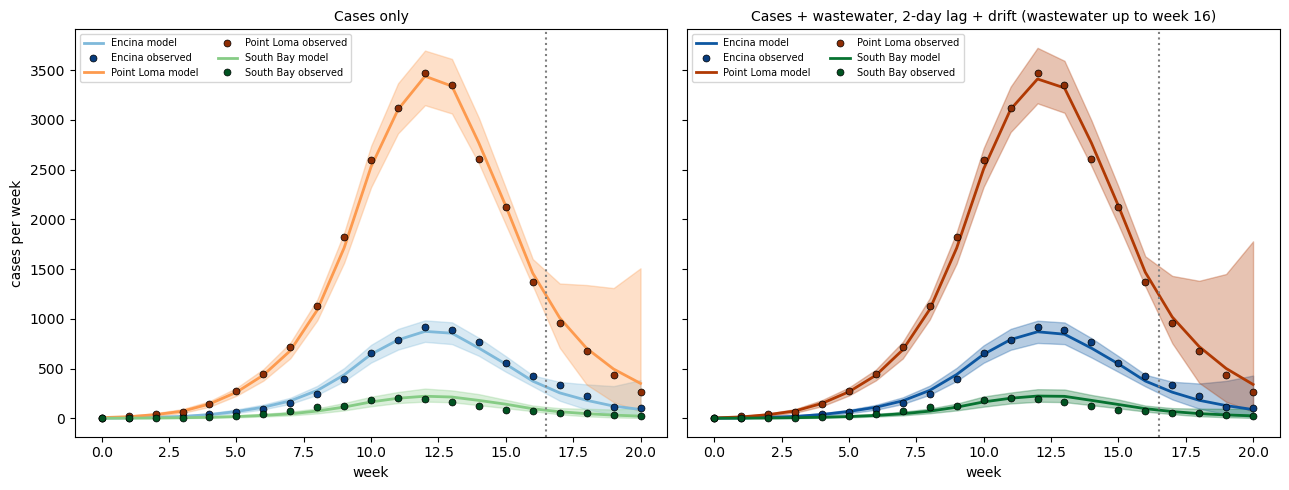

In [67]:
import numpy as np
import matplotlib.pyplot as plt

hues = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens]             # one hue per catchment
panels = {"Cases only": (idatas3["cases only"], 0.45),
          "Cases + wastewater, 2-day lag + drift (wastewater up to week 16)": (idatas3["ww aligned + drift"], 0.85)}
n_train, n_weeks = S["n_train"], S["n_weeks"]
weeks = np.arange(n_weeks)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, (idata, shade)) in zip(axes, panels.items()):
    lo, mid, hi = catchment_bands(idata)
    for k in range(len(codes)):
        colour = hues[k](shade)
        ax.fill_between(weeks, lo[k], hi[k], color=colour, alpha=0.30)
        ax.plot(weeks, mid[k], color=colour, lw=2, label=f"{catchment_names[k]} model")
        ax.plot(weeks, cases_catchment[k], "o", color=hues[k](0.95), ms=5,
                markeredgecolor="k", markeredgewidth=0.5, label=f"{catchment_names[k]} observed")
    ax.axvline(n_train - 0.5, color="grey", ls=":")
    ax.set_title(title, fontsize=10); ax.set_xlabel("week")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
axes[0].set_ylabel("cases per week")
plt.tight_layout(); plt.show()